In [5]:
import pandas as pd 
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr, spearmanr
import random
from scipy import stats
import matplotlib.pyplot as plt
import itertools
import numpy as np
import time
import os
import tqdm
import pandas as pd
import statsmodels.formula.api as smf
import warnings
from statsmodels.tools.sm_exceptions import (
    ConvergenceWarning,
    SingularMatrixWarning,
)

figure_dir="/home/jhu/jkim789/projects_aphill27/projects/pooch/figures"

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
import seaborn as sns
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "Arial"
})

In [6]:
file= "/path/to/project/pooch/findings/xist_interaction_all_cpg/chrX.cpg_interaction.tsv"
# file = "/path/to/project/pooch/findings/xist_interaction_all_cpg/chrX.cpg_interaction_mixedmodel.tsv"

df = pd.read_csv(file,
sep ='\t', header = 0)
df.head(2)

,chr,cpg,n_pairs,haplotype_coef,interaction_coef,haplotype_pvalue,interaction_pvalue,haplotype_fdr,interaction_fdr
0,chrX,946,0,NaN,NaN,NaN,NaN,NaN,NaN
1,chrX,11007,48,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df['-log_interaction_fdr'] = -np.log(df['interaction_fdr']) * np.sign(df['interaction_coef'])
df['-log_haplotype_fdr'] = -np.log(df['haplotype_fdr'])* np.sign(df['haplotype_coef'])

df['coef'] = ""
df.loc[df['cpg'].between(152054755,152054786), "coef"] = "within cluster"
df.loc[df['cpg'].between(1937652,1938190), "coef"] = "within cluster"
df = df.sort_values(by = 'coef')
df.head(2)

,chr,cpg,n_pairs,haplotype_coef,interaction_coef,haplotype_pvalue,interaction_pvalue,haplotype_fdr,interaction_fdr,-log_interaction_fdr,-log_haplotype_fdr,coef
0,chrX,946,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,chrX,11007,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

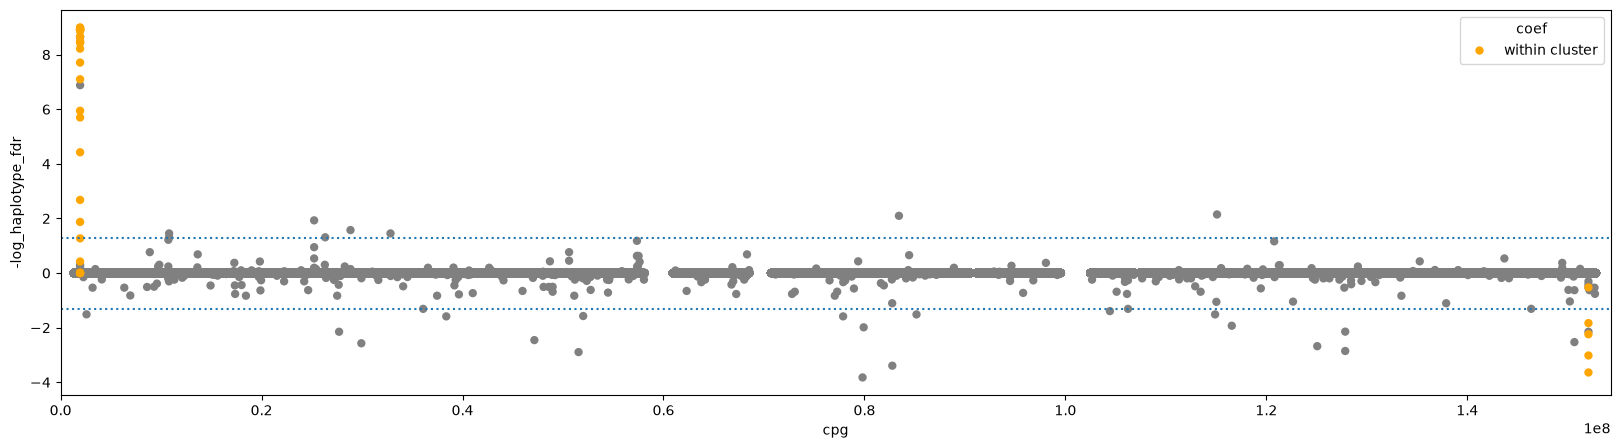

In [10]:
plt.figure(figsize=(20,5))
# sns.scatterplot(df, x= 'cpg', y = 'haplotype_coef',linewidth=0.3)
sns.scatterplot(df, x= 'cpg', y = '-log_haplotype_fdr',linewidth=0, 
hue = "coef", palette = {"" : "grey","within cluster" : "orange"}, rasterized=True)

plt.xlim(0,154259566)
plt.axhline(-np.log10(0.05), linestyle=":")
plt.axhline(np.log10(0.05), linestyle=":")

plt.savefig("/home/jhu/jkim789/projects_aphill27/projects/pooch/figures/all_cpg_interaction_haplotype_mixed.pdf")


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

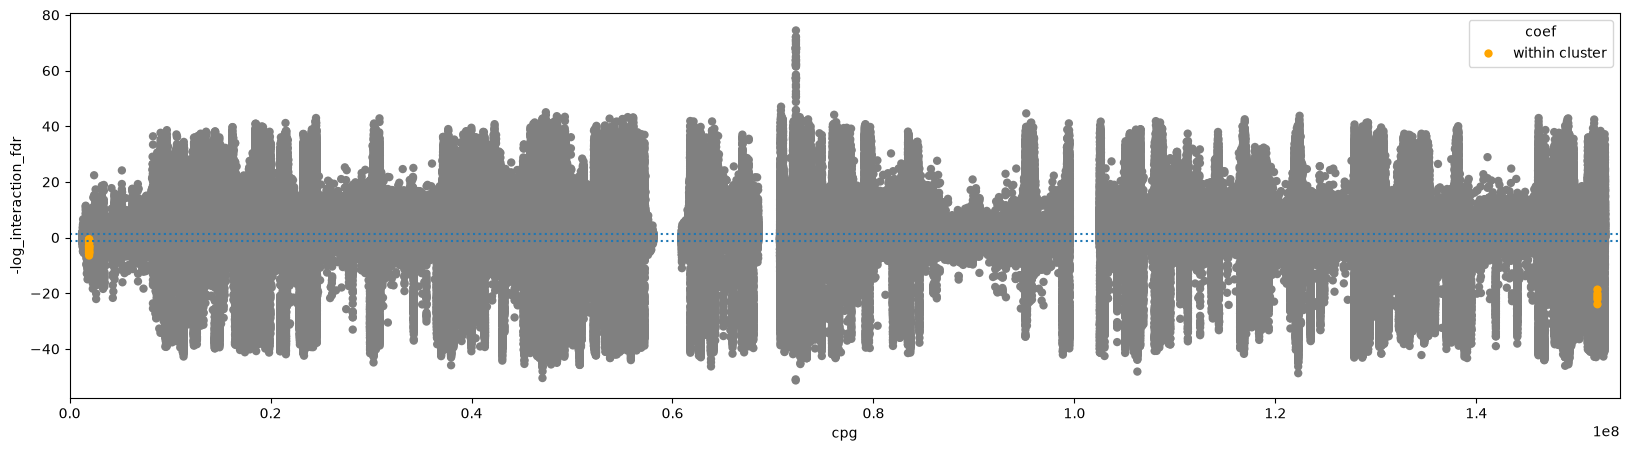

In [11]:
plt.figure(figsize=(20,5))
# sns.scatterplot(df, x= 'cpg', y = 'haplotype_coef',linewidth=0.3)
sns.scatterplot(df, x= 'cpg', y = '-log_interaction_fdr',linewidth=0, 
hue = "coef", palette = {"" : "grey","within cluster" : "orange"},rasterized=True)

plt.xlim(0,154259566)
plt.axhline(-np.log10(0.05), linestyle=":")
plt.axhline(np.log10(0.05), linestyle=":")

plt.savefig("/home/jhu/jkim789/projects_aphill27/projects/pooch/figures/all_cpg_interaction_interaction_term_mixed.pdf")